<a href="https://colab.research.google.com/github/omrani-wiem/crypto_price_prediction/blob/main/crypto_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import kagglehub
yassinebenzekri_crypto_path = kagglehub.dataset_download('yassinebenzekri/crypto')

print('Data source import complete.')


100%|██████████| 31.2M/31.2M [00:00<00:00, 91.7MB/s]

Extracting files...


Data source import complete.


In [ ]:

!pip install -q optuna

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns

from scipy.stats import shapiro
from scipy.stats import kstest
from scipy.stats import norm
import statsmodels.api as sm

import optuna
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

plt.style.use('ggplot')

In [ ]:
import os

# Utilisation du chemin téléchargé par kagglehub
data_dir = yassinebenzekri_crypto_path

Close = pd.read_csv(os.path.join(data_dir, "close.csv"))
High = pd.read_csv(os.path.join(data_dir, "high.csv"))
Low = pd.read_csv(os.path.join(data_dir, "low.csv"))
Open = pd.read_csv(os.path.join(data_dir, "open.csv"))
Volume = pd.read_csv(os.path.join(data_dir, "volume.csv"))

In [ ]:
Close.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10992 entries, 0 to 10991
Columns: 128 entries, Unnamed: 0 to ZRXUSDT
dtypes: float64(127), object(1)
memory usage: 10.7+ MB


In [ ]:
Volume.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10992 entries, 0 to 10991
Columns: 128 entries, Unnamed: 0 to ZRXUSDT
dtypes: float64(127), object(1)
memory usage: 10.7+ MB


In [ ]:
#information sur open
Open.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10992 entries, 0 to 10991
Columns: 128 entries, Unnamed: 0 to ZRXUSDT
dtypes: float64(127), object(1)
memory usage: 10.7+ MB


on travaille generalement avec les informations qui se trouve dans Open:

In [ ]:
#les cinq premiers
Open.head()

,Unnamed: 0,1000SHIBUSDT,1000XECUSDT,1INCHUSDT,AAVEUSDT,ADAUSDT,ALGOUSDT,ALICEUSDT,ALPHAUSDT,ANKRUSDT,...,XEMUSDT,XLMUSDT,XMRUSDT,XRPUSDT,XTZUSDT,YFIUSDT,ZECUSDT,ZENUSDT,ZILUSDT,ZRXUSDT
0,2021-06-01 00:00:00,0.009403,NaN,3.1777,376.52,1.7002,0.9164,7.226,0.8469,0.10439,...,0.1889,0.39402,272.01,1.0111,3.542,46455.4,158.15,107.525,0.11350,1.0054
1,2021-06-01 01:00:00,0.009278,NaN,3.2128,383.13,1.7402,0.9369,7.431,0.8676,0.10638,...,0.1951,0.40272,272.91,1.0459,3.606,46973.5,162.25,107.785,0.11551,1.0210
2,2021-06-01 02:00:00,0.009193,NaN,3.2544,385.81,1.7719,0.9399,7.599,0.8827,0.10847,...,0.1963,0.41357,273.26,1.0905,3.605,47365.7,163.18,111.316,0.11729,1.0258
3,2021-06-01 03:00:00,0.009095,NaN,3.1696,377.43,1.7275,0.9185,7.310,0.8548,0.10668,...,0.1922,0.40129,267.61,1.0601,3.541,46123.1,158.51,108.772,0.11468,0.9961
4,2021-06-01 04:00:00,0.009043,NaN,3.1456,382.25,1.7113,0.9164,7.218,0.8509,0.10767,...,0.1916,0.40234,270.87,1.0445,3.541,45830.4,157.07,107.613,0.11396,1.0019


In [ ]:
#descriptipn
Open.describe()

,1000SHIBUSDT,1000XECUSDT,1INCHUSDT,AAVEUSDT,ADAUSDT,ALGOUSDT,ALICEUSDT,ALPHAUSDT,ANKRUSDT,ANTUSDT,...,XEMUSDT,XLMUSDT,XMRUSDT,XRPUSDT,XTZUSDT,YFIUSDT,ZECUSDT,ZENUSDT,ZILUSDT,ZRXUSDT
count,10992.000000,8396.000000,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000,5971.000000,...,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000,10992.000000
mean,0.019872,0.098871,2.102563,209.620022,1.263301,0.997991,8.400483,0.551161,0.075847,4.006560,...,0.118135,0.236829,208.330772,0.741749,3.595072,23993.123735,124.448204,52.384709,0.073593,0.714977
std,0.013732,0.059343,1.109594,101.648447,0.652843,0.542270,5.160177,0.355698,0.030511,2.675575,...,0.052556,0.089883,49.870137,0.276730,1.654891,11079.156475,41.894544,27.798080,0.029981,0.286056
min,0.004948,0.028040,0.521700,46.130000,0.406900,0.280000,1.844000,0.095400,0.023300,1.180000,...,0.035700,0.099220,99.390000,0.294300,1.210000,4103.000000,50.670000,12.462000,0.029890,0.225400
25%,0.008392,0.046810,1.074500,115.060000,0.655400,0.583050,3.555500,0.221000,0.050257,1.745000,...,0.062575,0.149960,167.090000,0.514900,2.173000,13986.500000,94.787500,25.884500,0.045640,0.471350
50%,0.013131,0.081835,2.007850,190.245000,1.193050,0.886850,6.969000,0.458700,0.077080,3.587000,...,0.116200,0.236735,207.185000,0.761500,3.251000,24857.000000,123.785000,50.507500,0.070675,0.722650
75%,0.027224,0.117855,2.919750,299.410000,1.656225,1.438525,12.583750,0.861725,0.096850,5.283500,...,0.166200,0.316293,250.990000,0.942975,4.488250,33347.500000,152.792500,74.794750,0.098863,0.951400
max,0.086259,0.269880,6.712600,445.740000,3.099400,2.440600,28.494000,1.495100,0.206090,13.866000,...,0.243600,0.433840,339.000000,1.413700,8.987000,47365.700000,302.500000,133.926000,0.218280,1.513800


In [ ]:
#les 5 dernieres lignes
Open.tail()

,Unnamed: 0,1000SHIBUSDT,1000XECUSDT,1INCHUSDT,AAVEUSDT,ADAUSDT,ALGOUSDT,ALICEUSDT,ALPHAUSDT,ANKRUSDT,...,XEMUSDT,XLMUSDT,XMRUSDT,XRPUSDT,XTZUSDT,YFIUSDT,ZECUSDT,ZENUSDT,ZILUSDT,ZRXUSDT
10987,2022-09-01 19:00:00,0.011997,0.04522,0.6502,84.09,0.4498,0.2882,1.986,0.1195,0.03401,...,0.0427,0.10290,151.55,0.3245,1.498,8993.0,57.67,15.506,0.03549,0.2909
10988,2022-09-01 20:00:00,0.012051,0.04531,0.6533,84.47,0.4524,0.2880,1.993,0.1199,0.03409,...,0.0429,0.10322,151.48,0.3270,1.500,8994.0,57.87,15.519,0.03560,0.2917
10989,2022-09-01 21:00:00,0.012082,0.04571,0.6566,85.29,0.4528,0.2895,2.009,0.1204,0.03439,...,0.0429,0.10385,151.68,0.3295,1.507,9032.0,58.20,15.606,0.03566,0.2927
10990,2022-09-01 22:00:00,0.012233,0.04596,0.6631,86.00,0.4561,0.2918,2.030,0.1216,0.03475,...,0.0435,0.10427,152.87,0.3320,1.522,9173.0,59.13,15.701,0.03596,0.2953
10991,2022-09-01 23:00:00,0.012271,0.04605,0.6651,86.52,0.4567,0.2916,2.035,0.1220,0.03483,...,0.0437,0.10453,153.94,0.3318,1.529,9274.0,59.28,15.712,0.03616,0.2954


In [ ]:
#donne les noms des colonne de Open
print(Open.columns.tolist())

['Unnamed: 0', '1000SHIBUSDT', '1000XECUSDT', '1INCHUSDT', 'AAVEUSDT', 'ADAUSDT', 'ALGOUSDT', 'ALICEUSDT', 'ALPHAUSDT', 'ANKRUSDT', 'ANTUSDT', 'ARPAUSDT', 'ARUSDT', 'ATAUSDT', 'ATOMUSDT', 'AUDIOUSDT', 'AVAXUSDT', 'AXSUSDT', 'BAKEUSDT', 'BALUSDT', 'BANDUSDT', 'BATUSDT', 'BCHUSDT', 'BELUSDT', 'BLZUSDT', 'BNBUSDT', 'BTCDOMUSDT', 'BTCUSDT', 'C98USDT', 'CELOUSDT', 'CELRUSDT', 'CHRUSDT', 'CHZUSDT', 'COMPUSDT', 'COTIUSDT', 'CRVUSDT', 'CTKUSDT', 'CTSIUSDT', 'CVCUSDT', 'DASHUSDT', 'DEFIUSDT', 'DENTUSDT', 'DGBUSDT', 'DOGEUSDT', 'DOTUSDT', 'DUSKUSDT', 'DYDXUSDT', 'EGLDUSDT', 'ENJUSDT', 'ENSUSDT', 'EOSUSDT', 'ETCUSDT', 'ETHUSDT', 'FILUSDT', 'FLMUSDT', 'FTMUSDT', 'GALAUSDT', 'GRTUSDT', 'GTCUSDT', 'HBARUSDT', 'HNTUSDT', 'HOTUSDT', 'ICPUSDT', 'ICXUSDT', 'IOSTUSDT', 'IOTAUSDT', 'IOTXUSDT', 'KAVAUSDT', 'KLAYUSDT', 'KNCUSDT', 'KSMUSDT', 'LINAUSDT', 'LINKUSDT', 'LITUSDT', 'LPTUSDT', 'LRCUSDT', 'LTCUSDT', 'MANAUSDT', 'MASKUSDT', 'MATICUSDT', 'MKRUSDT', 'MTLUSDT', 'NEARUSDT', 'NEOUSDT', 'NKNUSDT', 'OCEANUS

In [ ]:
# renaming the first column in each data frame 'date'

for data in [Close, High, Low, Open, Volume]:
    data.rename(columns={'Unnamed: 0':'date'}, inplace=True)

In [ ]:
#on l'affiche une autre fois pour verifier
print(Open.columns.tolist())

['date', '1000SHIBUSDT', '1000XECUSDT', '1INCHUSDT', 'AAVEUSDT', 'ADAUSDT', 'ALGOUSDT', 'ALICEUSDT', 'ALPHAUSDT', 'ANKRUSDT', 'ANTUSDT', 'ARPAUSDT', 'ARUSDT', 'ATAUSDT', 'ATOMUSDT', 'AUDIOUSDT', 'AVAXUSDT', 'AXSUSDT', 'BAKEUSDT', 'BALUSDT', 'BANDUSDT', 'BATUSDT', 'BCHUSDT', 'BELUSDT', 'BLZUSDT', 'BNBUSDT', 'BTCDOMUSDT', 'BTCUSDT', 'C98USDT', 'CELOUSDT', 'CELRUSDT', 'CHRUSDT', 'CHZUSDT', 'COMPUSDT', 'COTIUSDT', 'CRVUSDT', 'CTKUSDT', 'CTSIUSDT', 'CVCUSDT', 'DASHUSDT', 'DEFIUSDT', 'DENTUSDT', 'DGBUSDT', 'DOGEUSDT', 'DOTUSDT', 'DUSKUSDT', 'DYDXUSDT', 'EGLDUSDT', 'ENJUSDT', 'ENSUSDT', 'EOSUSDT', 'ETCUSDT', 'ETHUSDT', 'FILUSDT', 'FLMUSDT', 'FTMUSDT', 'GALAUSDT', 'GRTUSDT', 'GTCUSDT', 'HBARUSDT', 'HNTUSDT', 'HOTUSDT', 'ICPUSDT', 'ICXUSDT', 'IOSTUSDT', 'IOTAUSDT', 'IOTXUSDT', 'KAVAUSDT', 'KLAYUSDT', 'KNCUSDT', 'KSMUSDT', 'LINAUSDT', 'LINKUSDT', 'LITUSDT', 'LPTUSDT', 'LRCUSDT', 'LTCUSDT', 'MANAUSDT', 'MASKUSDT', 'MATICUSDT', 'MKRUSDT', 'MTLUSDT', 'NEARUSDT', 'NEOUSDT', 'NKNUSDT', 'OCEANUSDT', '

In [ ]:
# checking the missing values

missing_values = Open.isna().sum()
for column, count in missing_values .items():
        print(f"{column}: {count}")

date: 0
1000SHIBUSDT: 0
1000XECUSDT: 2596
1INCHUSDT: 0
AAVEUSDT: 0
ADAUSDT: 0
ALGOUSDT: 0
ALICEUSDT: 0
ALPHAUSDT: 0
ANKRUSDT: 0
ANTUSDT: 5021
ARPAUSDT: 3364
ARUSDT: 2860
ATAUSDT: 2188
ATOMUSDT: 0
AUDIOUSDT: 1900
AVAXUSDT: 0
AXSUSDT: 0
BAKEUSDT: 0
BALUSDT: 0
BANDUSDT: 0
BATUSDT: 0
BCHUSDT: 0
BELUSDT: 0
BLZUSDT: 0
BNBUSDT: 0
BTCDOMUSDT: 484
BTCUSDT: 0
C98USDT: 2020
CELOUSDT: 2836
CELRUSDT: 0
CHRUSDT: 0
CHZUSDT: 0
COMPUSDT: 0
COTIUSDT: 0
CRVUSDT: 0
CTKUSDT: 0
CTSIUSDT: 3532
CVCUSDT: 0
DASHUSDT: 0
DEFIUSDT: 0
DENTUSDT: 0
DGBUSDT: 0
DOGEUSDT: 0
DOTUSDT: 0
DUSKUSDT: 5284
DYDXUSDT: 2428
EGLDUSDT: 0
ENJUSDT: 0
ENSUSDT: 4372
EOSUSDT: 0
ETCUSDT: 0
ETHUSDT: 0
FILUSDT: 0
FLMUSDT: 0
FTMUSDT: 0
GALAUSDT: 2620
GRTUSDT: 0
GTCUSDT: 244
HBARUSDT: 0
HNTUSDT: 0
HOTUSDT: 0
ICPUSDT: 10992
ICXUSDT: 0
IOSTUSDT: 0
IOTAUSDT: 0
IOTXUSDT: 1732
KAVAUSDT: 0
KLAYUSDT: 3196
KNCUSDT: 0
KSMUSDT: 0
LINAUSDT: 0
LINKUSDT: 0
LITUSDT: 0
LPTUSDT: 3916
LRCUSDT: 0
LTCUSDT: 0
MANAUSDT: 0
MASKUSDT: 2092
MATICUSDT: 0
MKRUSDT: 0
M

In [ ]:
#affiche uniquement les colonnes avec missing values
missing_values = Open.isna().sum()
for column, count in missing_values .items():
    if count>0:
        print(f"{column}: {count}")

1000XECUSDT: 2596
ANTUSDT: 5021
ARPAUSDT: 3364
ARUSDT: 2860
ATAUSDT: 2188
AUDIOUSDT: 1900
BTCDOMUSDT: 484
C98USDT: 2020
CELOUSDT: 2836
CTSIUSDT: 3532
DUSKUSDT: 5284
DYDXUSDT: 2428
ENSUSDT: 4372
GALAUSDT: 2620
GTCUSDT: 244
ICPUSDT: 10992
IOTXUSDT: 1732
KLAYUSDT: 3196
LPTUSDT: 3916
MASKUSDT: 2092
PEOPLEUSDT: 4949
RAYUSDT: 1924
ROSEUSDT: 5116


In [ ]:
#affiche uniquement les colonnes avec missing values
missing_values = Open.isna().sum()
for column, count in missing_values .items():
    if count==0:
        print(f"{column}: {count}")

date: 0
1000SHIBUSDT: 0
1INCHUSDT: 0
AAVEUSDT: 0
ADAUSDT: 0
ALGOUSDT: 0
ALICEUSDT: 0
ALPHAUSDT: 0
ANKRUSDT: 0
ATOMUSDT: 0
AVAXUSDT: 0
AXSUSDT: 0
BAKEUSDT: 0
BALUSDT: 0
BANDUSDT: 0
BATUSDT: 0
BCHUSDT: 0
BELUSDT: 0
BLZUSDT: 0
BNBUSDT: 0
BTCUSDT: 0
CELRUSDT: 0
CHRUSDT: 0
CHZUSDT: 0
COMPUSDT: 0
COTIUSDT: 0
CRVUSDT: 0
CTKUSDT: 0
CVCUSDT: 0
DASHUSDT: 0
DEFIUSDT: 0
DENTUSDT: 0
DGBUSDT: 0
DOGEUSDT: 0
DOTUSDT: 0
EGLDUSDT: 0
ENJUSDT: 0
EOSUSDT: 0
ETCUSDT: 0
ETHUSDT: 0
FILUSDT: 0
FLMUSDT: 0
FTMUSDT: 0
GRTUSDT: 0
HBARUSDT: 0
HNTUSDT: 0
HOTUSDT: 0
ICXUSDT: 0
IOSTUSDT: 0
IOTAUSDT: 0
KAVAUSDT: 0
KNCUSDT: 0
KSMUSDT: 0
LINAUSDT: 0
LINKUSDT: 0
LITUSDT: 0
LRCUSDT: 0
LTCUSDT: 0
MANAUSDT: 0
MATICUSDT: 0
MKRUSDT: 0
MTLUSDT: 0
NEARUSDT: 0
NEOUSDT: 0
NKNUSDT: 0
OCEANUSDT: 0
OGNUSDT: 0
OMGUSDT: 0
ONEUSDT: 0
ONTUSDT: 0
QTUMUSDT: 0
REEFUSDT: 0
RENUSDT: 0
RLCUSDT: 0
RSRUSDT: 0
RUNEUSDT: 0
RVNUSDT: 0
SANDUSDT: 0
SFPUSDT: 0
SKLUSDT: 0
SNXUSDT: 0
SOLUSDT: 0
SRMUSDT: 0
STMXUSDT: 0
STORJUSDT: 0
SUSHIUSDT: 0
SXPUSDT: 0

In [ ]:
#nombre de colonne ayant des valeurs manquantes dans Open
nombre = (Open.isnull().sum() > 0).sum()
print(nombre)

23


Lineplots of some coins with missing values

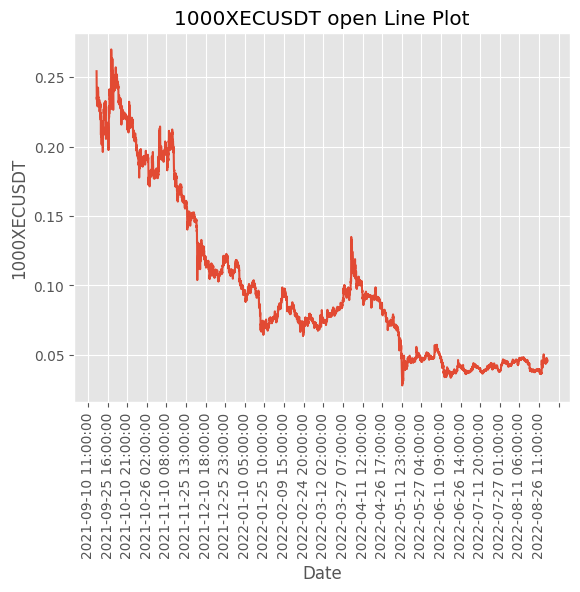

In [ ]:
# 1000XECUSDT open Line Plot
plt.plot(Open['date'], Open['1000XECUSDT'])
plt.xlabel('Date')
plt.ylabel('1000XECUSDT')
plt.title('1000XECUSDT open Line Plot')
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(interval=12))#This code gets the current plot, sets the positions for the main ticks on the x-axis, and places a tick every 12 months.
plt.xticks(rotation=90)#urns the text on the x-axis sideways so it's easier to read.
plt.show()

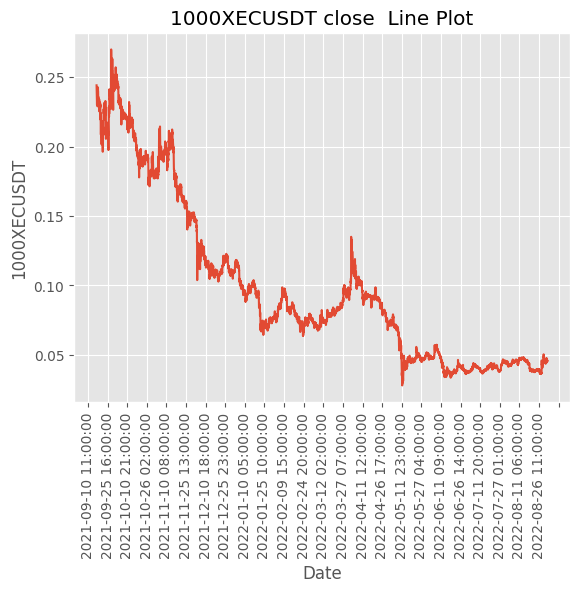

In [ ]:
#1000XECUSDT close  Line Plot
plt.plot(Close['date'], Close['1000XECUSDT'])
plt.xlabel('Date')
plt.ylabel('1000XECUSDT')
plt.title('1000XECUSDT close  Line Plot')
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(interval=12))
plt.xticks(rotation=90)
plt.show()

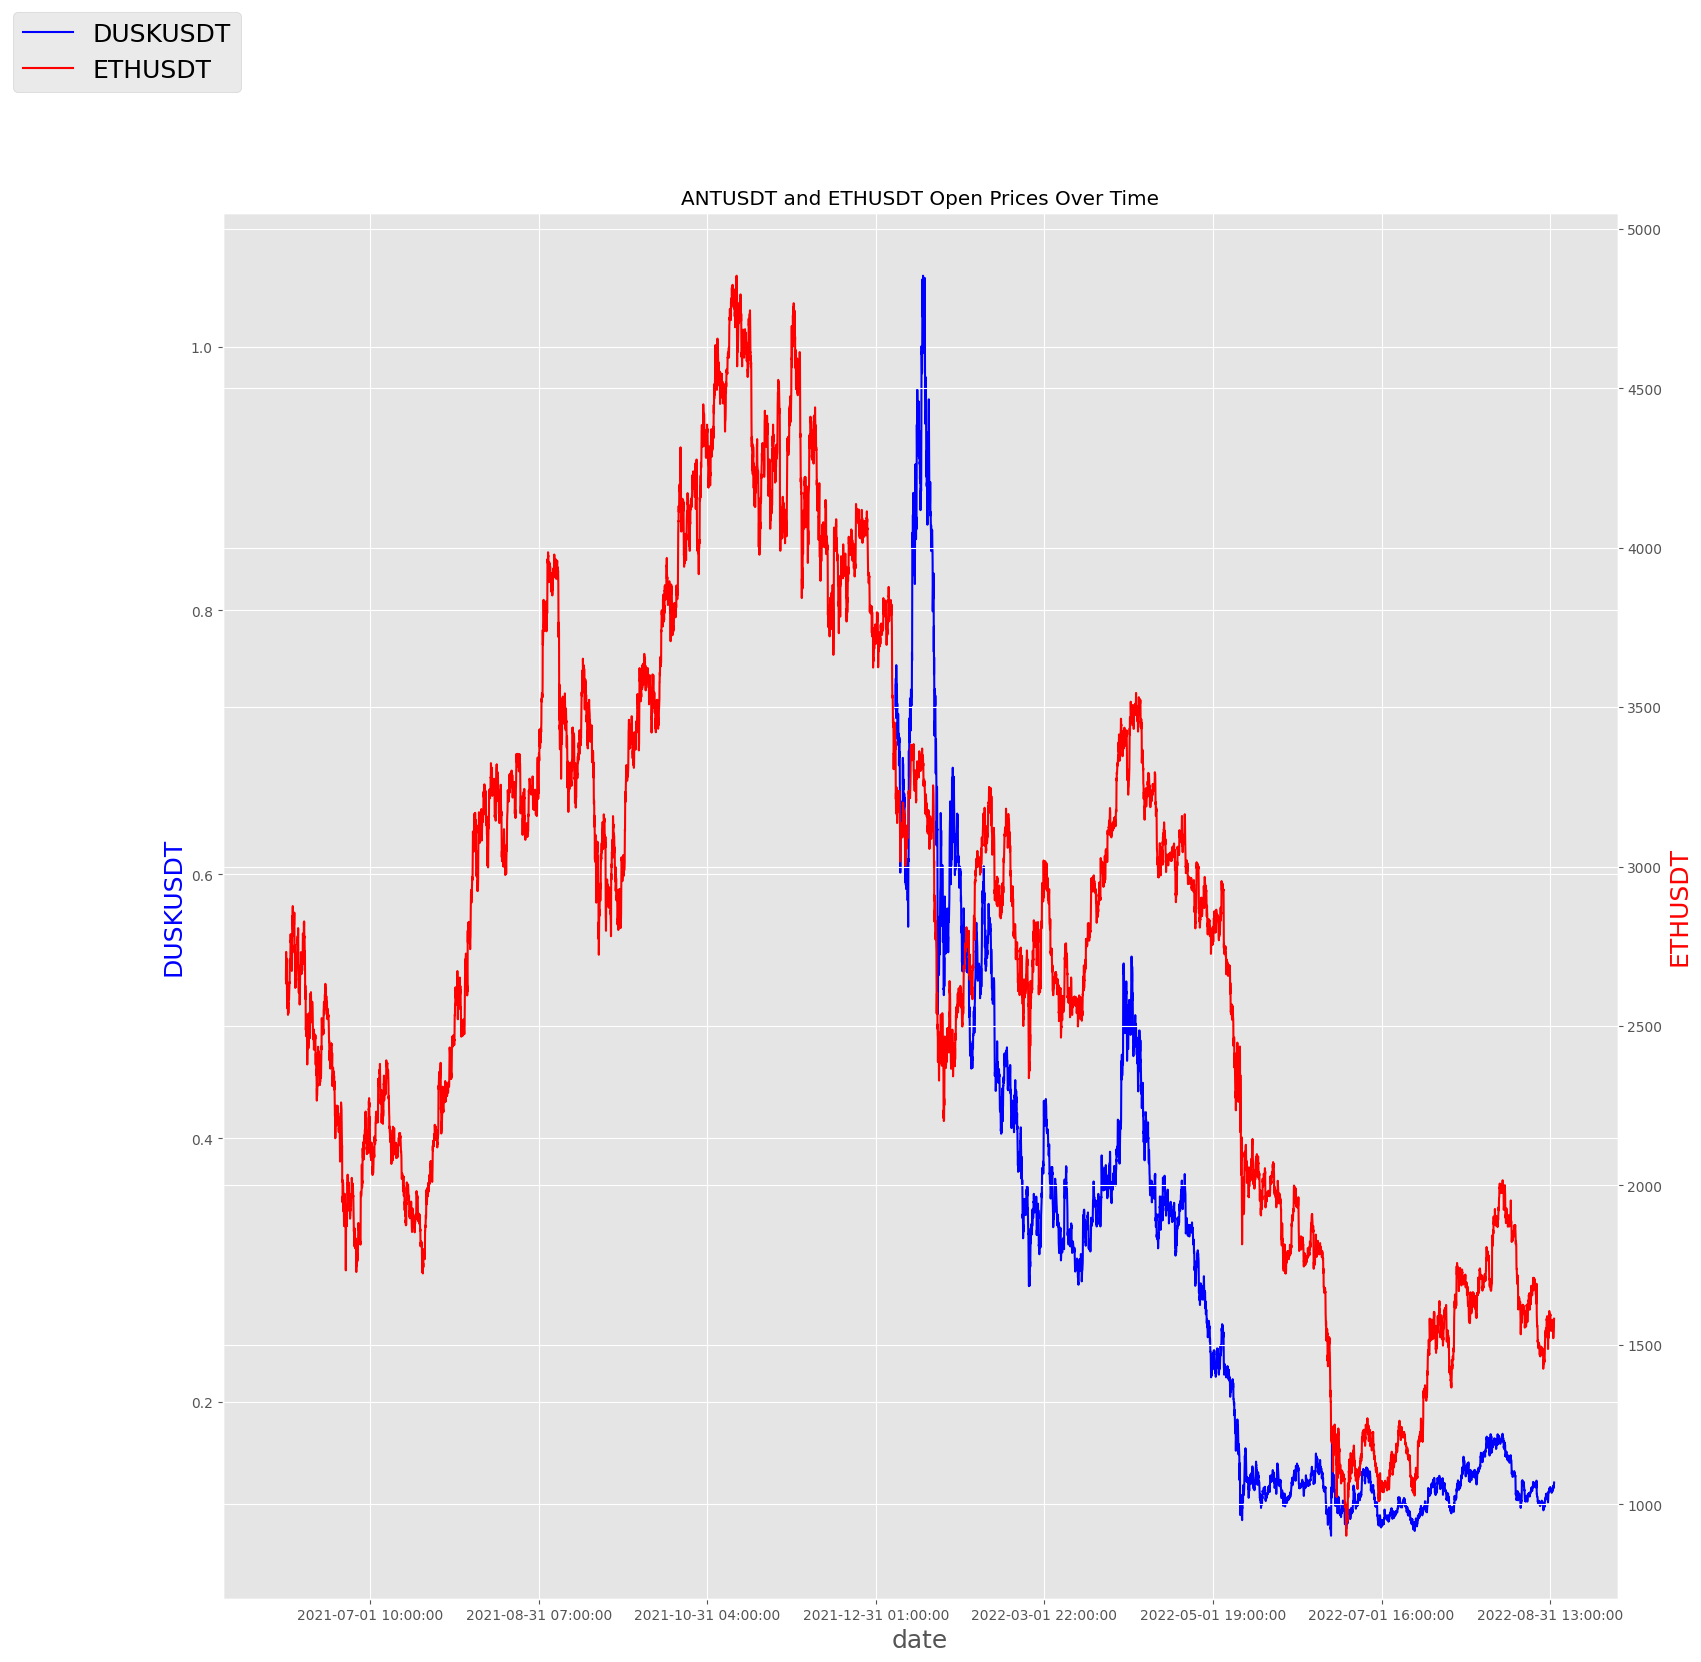

In [ ]:
# Comparison between the lineplots of DUSKUSDT(with missing values) and (ETHUSDT without missing values)

fig, ax1 = plt.subplots(figsize=(18, 18))
ax1.plot(Open['date'], Open['DUSKUSDT'], color='b', label='DUSKUSDT')
ax1.set_xlabel('date', fontsize=18)
ax1.set_ylabel('DUSKUSDT', color='b', fontsize=18)
ax2 = ax1.twinx()
ax2.plot(Open['date'], Open['ETHUSDT'], color='r', label='ETHUSDT')
ax2.set_ylabel('ETHUSDT', color='r', fontsize=18)
fig.legend(loc='upper left', fontsize=18)
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.AutoDateLocator())
plt.title('ANTUSDT and ETHUSDT Open Prices Over Time')
plt.show()

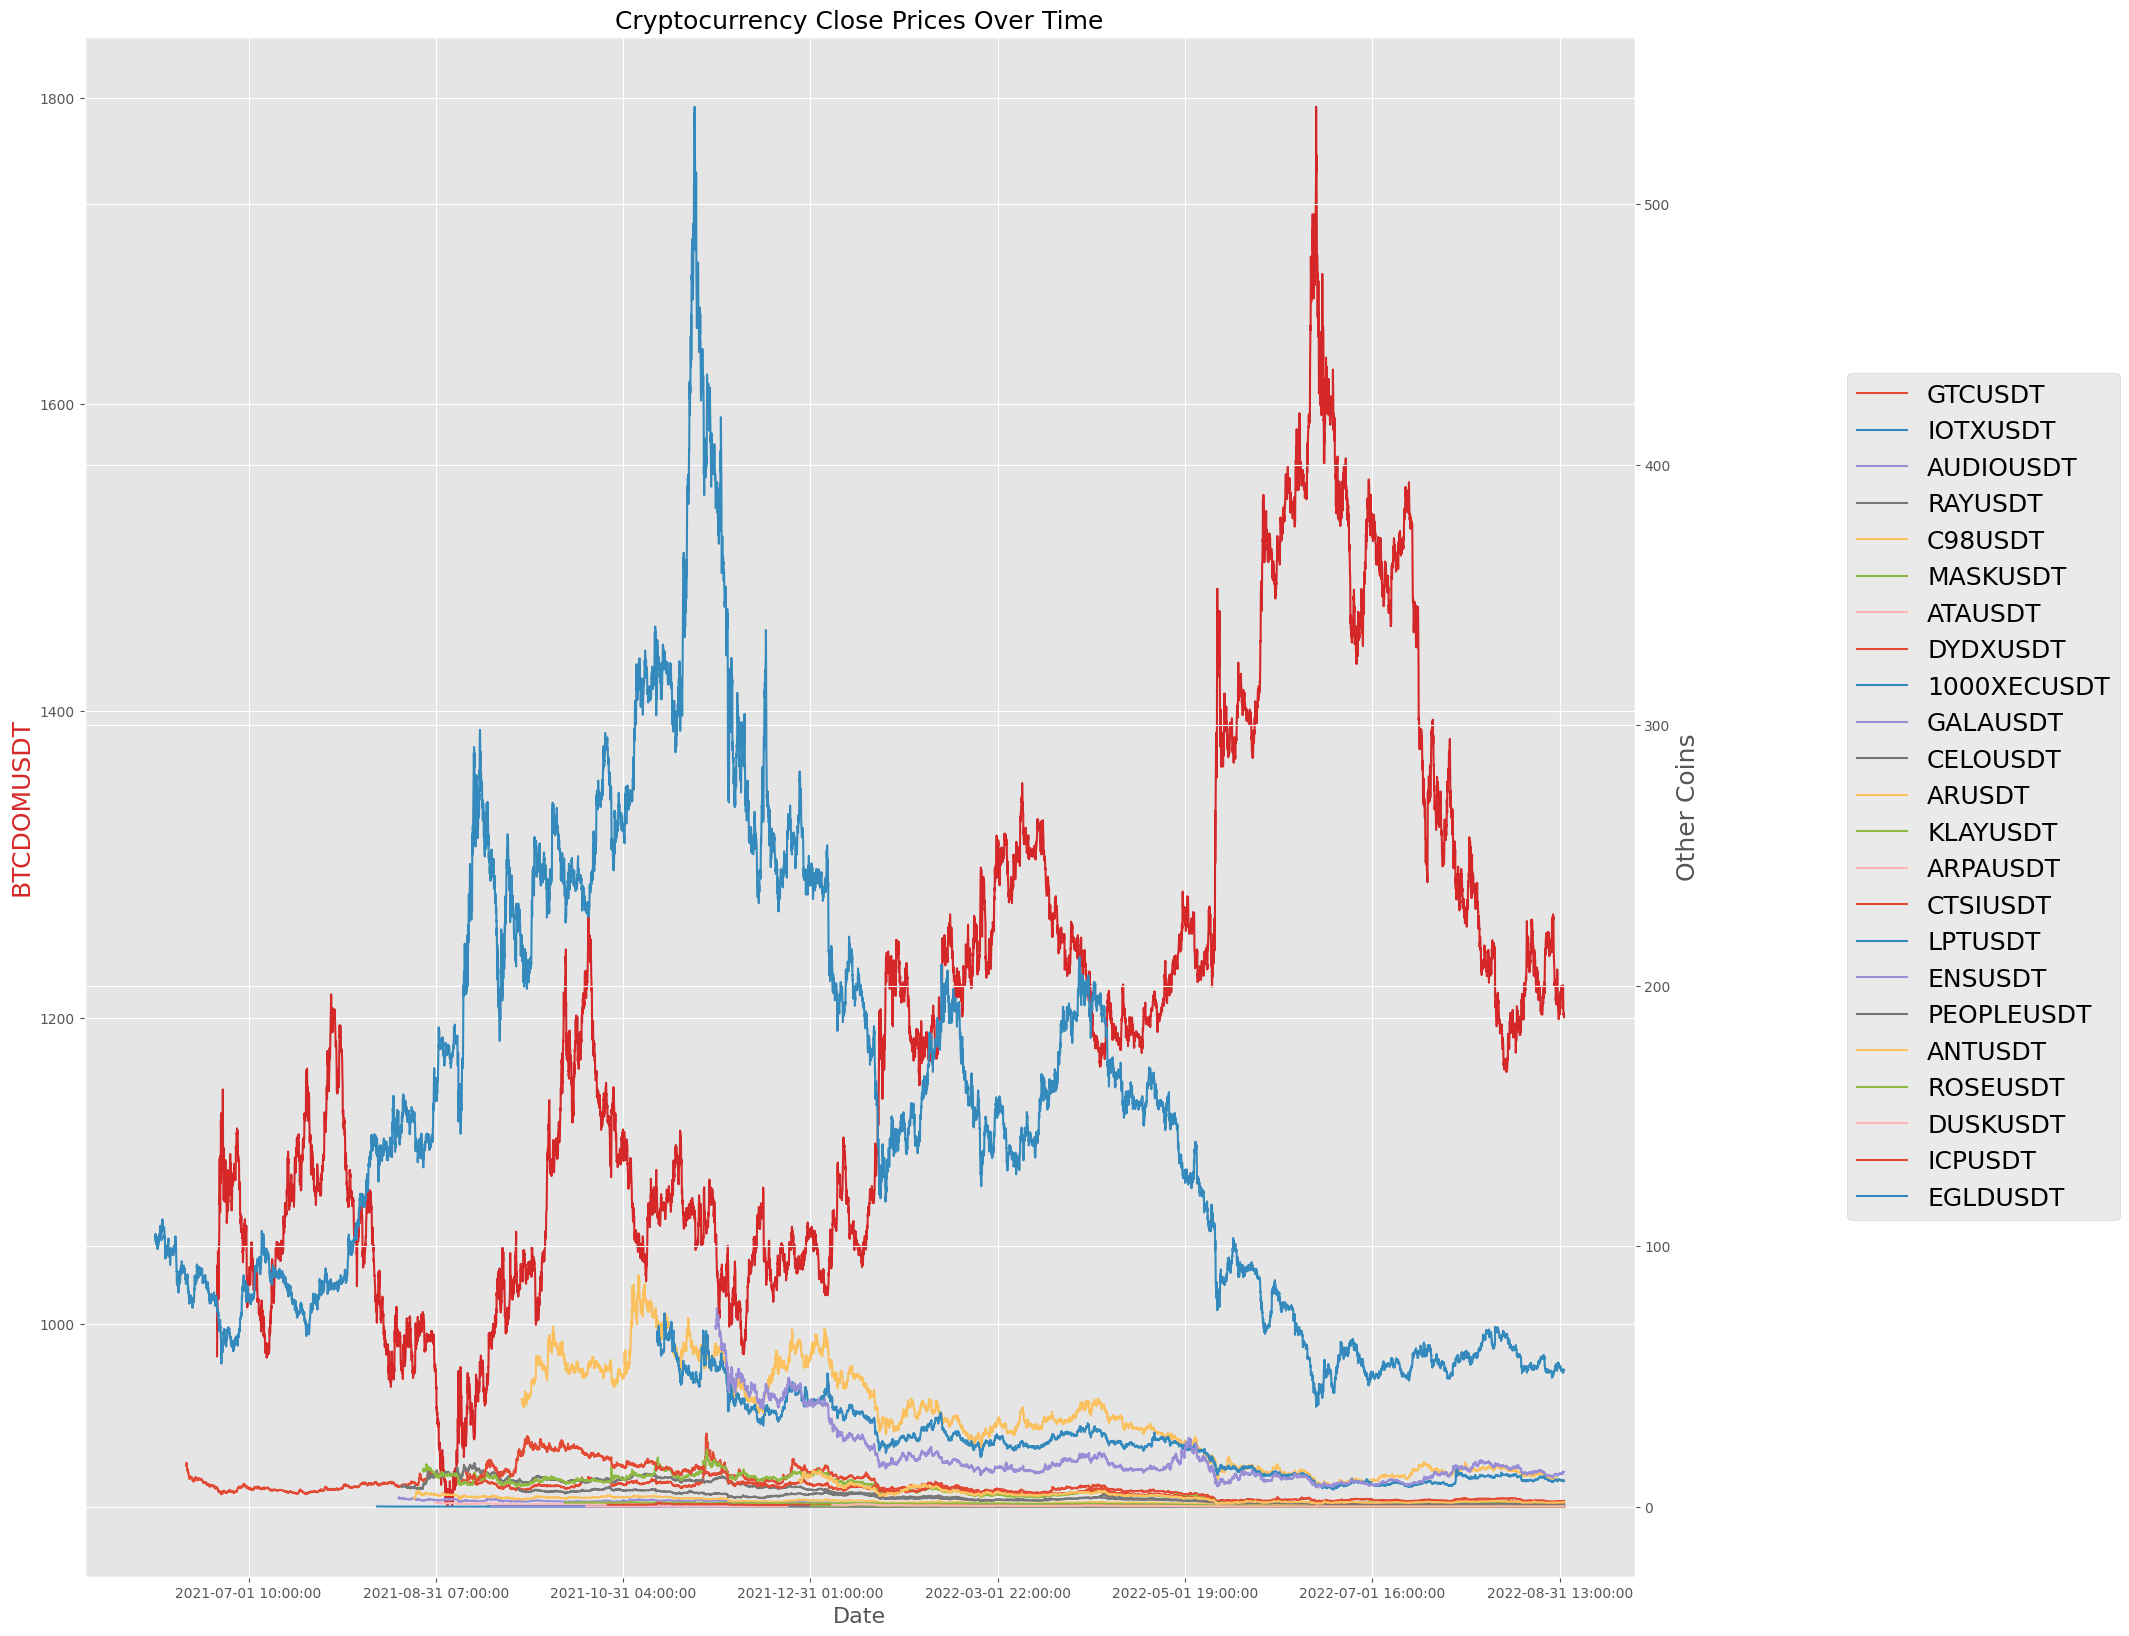

In [ ]:
# Close lineplots of the coins with missing values

selected_coins = ['GTCUSDT', 'BTCDOMUSDT', 'IOTXUSDT', 'AUDIOUSDT', 'RAYUSDT',
                   'C98USDT', 'MASKUSDT', 'ATAUSDT', 'DYDXUSDT', '1000XECUSDT',
                   'GALAUSDT', 'CELOUSDT', 'ARUSDT', 'KLAYUSDT', 'ARPAUSDT',
                   'CTSIUSDT', 'LPTUSDT', 'ENSUSDT', 'PEOPLEUSDT', 'ANTUSDT',
                   'ROSEUSDT', 'DUSKUSDT', 'ICPUSDT', 'EGLDUSDT']
fig, ax1 = plt.subplots(figsize=(20, 20))
ax1.set_xlabel('Date', fontsize=16)
ax1.set_ylabel('BTCDOMUSDT', color='tab:red', fontsize=18)
ax1.plot(Close['date'], Close['BTCDOMUSDT'], color='tab:red')
ax1.tick_params(axis='y')

ax2 = ax1.twinx()

for coin in selected_coins:
    if coin != 'BTCDOMUSDT':
        ax2.plot(Close['date'], Close[coin], label=coin)

ax2.set_ylabel('Other Coins', fontsize=18)
fig.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=18)
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.AutoDateLocator())
plt.title('Cryptocurrency Close Prices Over Time', fontsize=18)
plt.show()

In [ ]:
# Assurer le renommage de la colonne 'Unnamed: 0' en 'date'
for df in [Close, High, Low, Open, Volume]:
    if 'Unnamed: 0' in df.columns:
        df.rename(columns={'Unnamed: 0': 'date'}, inplace=True)

# Remplacement réaliste des valeurs manquantes par propagation (forward fill)
Close.fillna(method='ffill', inplace=True)
High.fillna(method='ffill', inplace=True)
Low.fillna(method='ffill', inplace=True)
Open.fillna(method='ffill', inplace=True)
Volume.fillna(method='ffill', inplace=True)

# Puis par 0 pour le reste
Close.fillna(0, inplace=True)
High.fillna(0, inplace=True)
Low.fillna(0, inplace=True)
Open.fillna(0, inplace=True)
Volume.fillna(0, inplace=True)

print("Remplacement des NaN terminé avec succès.")

Remplacement des NaN terminé avec succès.


In [ ]:
missing_values = Open.isna().sum()
for column, count in missing_values .items():
        print(f"{column}: {count}")

date: 0
1000SHIBUSDT: 0
1000XECUSDT: 0
1INCHUSDT: 0
AAVEUSDT: 0
ADAUSDT: 0
ALGOUSDT: 0
ALICEUSDT: 0
ALPHAUSDT: 0
ANKRUSDT: 0
ANTUSDT: 0
ARPAUSDT: 0
ARUSDT: 0
ATAUSDT: 0
ATOMUSDT: 0
AUDIOUSDT: 0
AVAXUSDT: 0
AXSUSDT: 0
BAKEUSDT: 0
BALUSDT: 0
BANDUSDT: 0
BATUSDT: 0
BCHUSDT: 0
BELUSDT: 0
BLZUSDT: 0
BNBUSDT: 0
BTCDOMUSDT: 0
BTCUSDT: 0
C98USDT: 0
CELOUSDT: 0
CELRUSDT: 0
CHRUSDT: 0
CHZUSDT: 0
COMPUSDT: 0
COTIUSDT: 0
CRVUSDT: 0
CTKUSDT: 0
CTSIUSDT: 0
CVCUSDT: 0
DASHUSDT: 0
DEFIUSDT: 0
DENTUSDT: 0
DGBUSDT: 0
DOGEUSDT: 0
DOTUSDT: 0
DUSKUSDT: 0
DYDXUSDT: 0
EGLDUSDT: 0
ENJUSDT: 0
ENSUSDT: 0
EOSUSDT: 0
ETCUSDT: 0
ETHUSDT: 0
FILUSDT: 0
FLMUSDT: 0
FTMUSDT: 0
GALAUSDT: 0
GRTUSDT: 0
GTCUSDT: 0
HBARUSDT: 0
HNTUSDT: 0
HOTUSDT: 0
ICPUSDT: 0
ICXUSDT: 0
IOSTUSDT: 0
IOTAUSDT: 0
IOTXUSDT: 0
KAVAUSDT: 0
KLAYUSDT: 0
KNCUSDT: 0
KSMUSDT: 0
LINAUSDT: 0
LINKUSDT: 0
LITUSDT: 0
LPTUSDT: 0
LRCUSDT: 0
LTCUSDT: 0
MANAUSDT: 0
MASKUSDT: 0
MATICUSDT: 0
MKRUSDT: 0
MTLUSDT: 0
NEARUSDT: 0
NEOUSDT: 0
NKNUSDT: 0
OCEANUSDT: 0
OG

In [ ]:
# Candlestick Chart of ETHUSDT
fig = go.Figure(data=[go.Candlestick(x=Open['date'],
                open=Open['ETHUSDT'],
                high=High['ETHUSDT'],
                low=Low['ETHUSDT'],
                close=Close['ETHUSDT'])])
fig.update_layout(
    title='Candlestick Chart of ETHUSDT ',
    xaxis_title='Date',
    yaxis_title='Price'
)
fig.show()

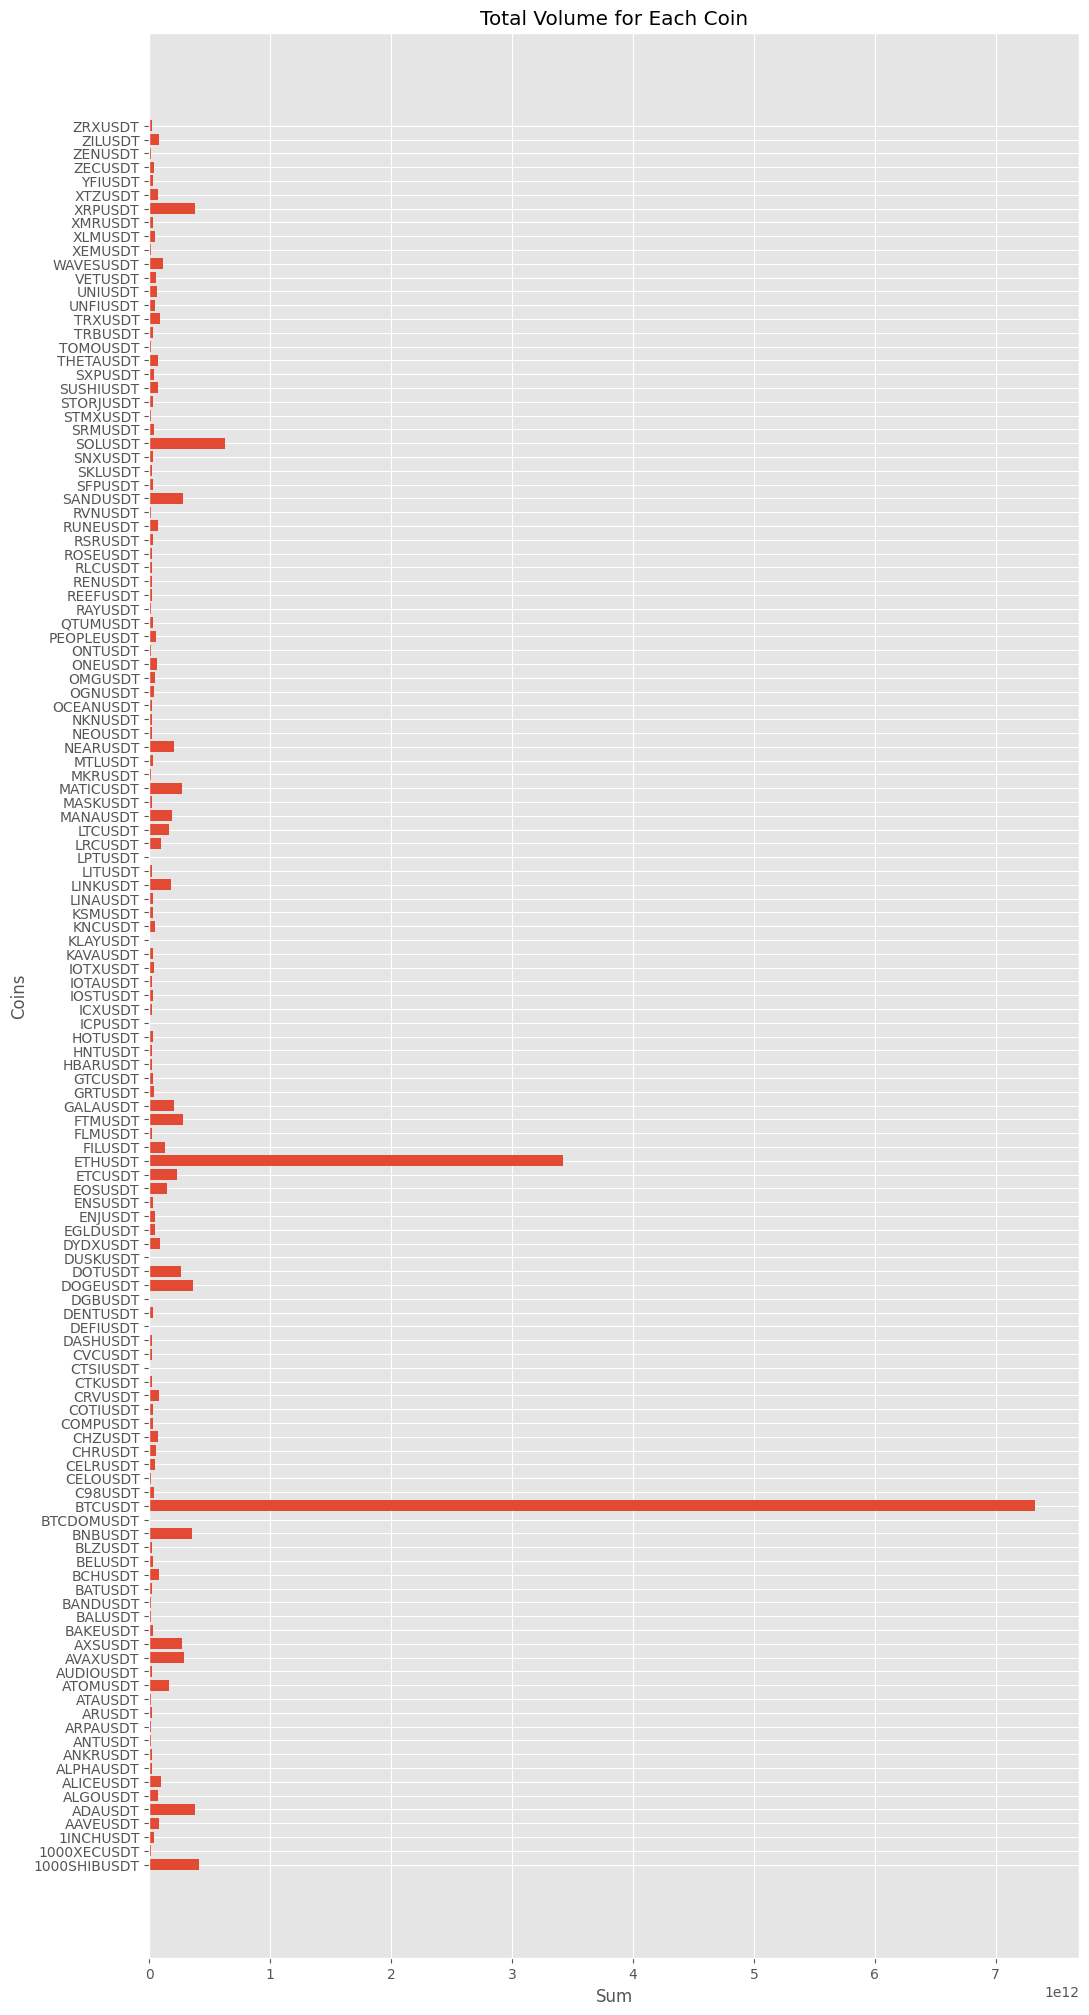

In [ ]:
# Bar plot of Total Volume per coin

volume =Volume.drop(Volume.columns[0], axis=1)
column_sums = volume.sum()
plt.figure(figsize=(12, 25))
plt.barh(column_sums.index, column_sums)
plt.title('Total Volume for Each Coin')
plt.xlabel('Sum')
plt.ylabel('Coins')
plt.show()

Selection of a coin: 'Butcusdt'

In [ ]:
# creation of a single data table with the columns high/low/open/close

BTCUSDT = pd.concat([Open['date'], Open['BTCUSDT'], Close['BTCUSDT'], High['BTCUSDT'], Low['BTCUSDT']], axis=1)
BTCUSDT.columns = ['date', 'open', 'close', 'high', 'low']
print(BTCUSDT)

                      date      open     close      high       low
0      2021-06-01 00:00:00  36881.53  37287.29  37500.00  36794.25
1      2021-06-01 01:00:00  37287.30  37780.96  37893.76  37100.00
2      2021-06-01 02:00:00  37780.96  37237.17  37787.94  37233.00
3      2021-06-01 03:00:00  37237.17  36831.99  37296.83  36600.00
4      2021-06-01 04:00:00  36832.00  36713.97  37118.71  36458.48
...                    ...       ...       ...       ...       ...
10987  2022-09-01 19:00:00  19728.50  19804.30  19930.00  19695.80
10988  2022-09-01 20:00:00  19804.20  19855.70  19892.60  19770.10
10989  2022-09-01 21:00:00  19855.60  20066.40  20093.30  19830.40
10990  2022-09-01 22:00:00  20066.40  20086.10  20153.60  20029.20
10991  2022-09-01 23:00:00  20086.10  20062.60  20171.00  20057.70

[10992 rows x 5 columns]


In [ ]:
#Calcul du rendement et l'ajouter comme une nouvelle colonne qui mesure la performance d'un investissement, indiquant s'il a rapporté ou perdu de l'argent.
BTCUSDT['rendement'] = BTCUSDT['close'] / BTCUSDT['open']
print(BTCUSDT)

                      date      open     close      high       low  rendement
0      2021-06-01 00:00:00  36881.53  37287.29  37500.00  36794.25   1.011002
1      2021-06-01 01:00:00  37287.30  37780.96  37893.76  37100.00   1.013239
2      2021-06-01 02:00:00  37780.96  37237.17  37787.94  37233.00   0.985607
3      2021-06-01 03:00:00  37237.17  36831.99  37296.83  36600.00   0.989119
4      2021-06-01 04:00:00  36832.00  36713.97  37118.71  36458.48   0.996795
...                    ...       ...       ...       ...       ...        ...
10987  2022-09-01 19:00:00  19728.50  19804.30  19930.00  19695.80   1.003842
10988  2022-09-01 20:00:00  19804.20  19855.70  19892.60  19770.10   1.002600
10989  2022-09-01 21:00:00  19855.60  20066.40  20093.30  19830.40   1.010617
10990  2022-09-01 22:00:00  20066.40  20086.10  20153.60  20029.20   1.000982
10991  2022-09-01 23:00:00  20086.10  20062.60  20171.00  20057.70   0.998830

[10992 rows x 6 columns]


#Étude de la normalité des rendements:#L'étude de la normalité des rendements vérifie leur symétrie autour de la moyenne pour faciliter les prévisions financières.

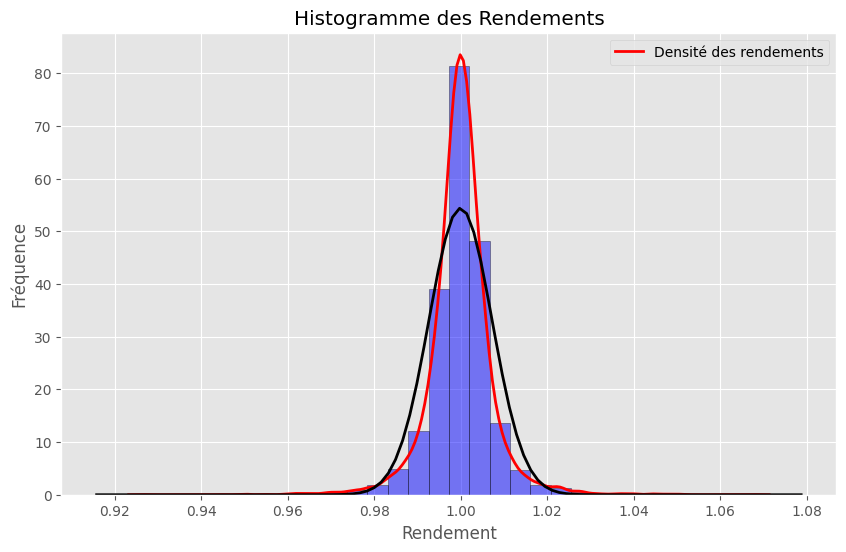

In [ ]:
#nbda nfhm apartir mena# L'histogramme et la densité des rendements de ''

plt.figure(figsize=(10, 6))
plt.hist(BTCUSDT['rendement'], bins=30, alpha=0.5, color='blue', edgecolor='black', density=True)
plt.title('Histogramme des Rendements')
plt.xlabel('Rendement')
plt.ylabel('Fréquence')
sns.kdeplot(BTCUSDT['rendement'], color='red', linestyle='-', linewidth=2)
plt.legend(['Densité des rendements'])


# Calculer la moyenne et l'écart type des rendements
mu, sigma = BTCUSDT['rendement'].mean(), BTCUSDT['rendement'].std()

# Tracer la densité de la loi normale
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, sigma)
plt.plot(x, p, 'k', linewidth=2)


plt.show()

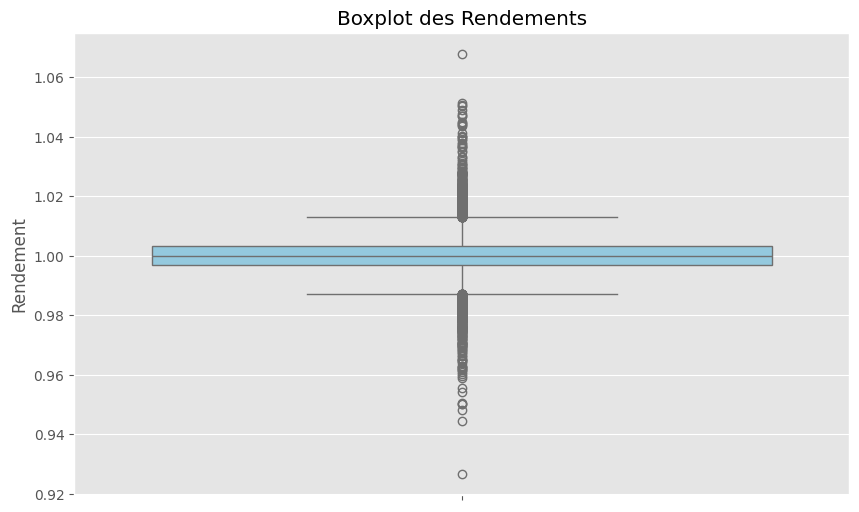

In [ ]:
# Boxplot des rendements

plt.figure(figsize=(10, 6))
sns.boxplot(data=BTCUSDT, y='rendement', color='skyblue')
plt.title('Boxplot des Rendements')
plt.ylabel('Rendement')
plt.show()

<Figure size 800x600 with 0 Axes>

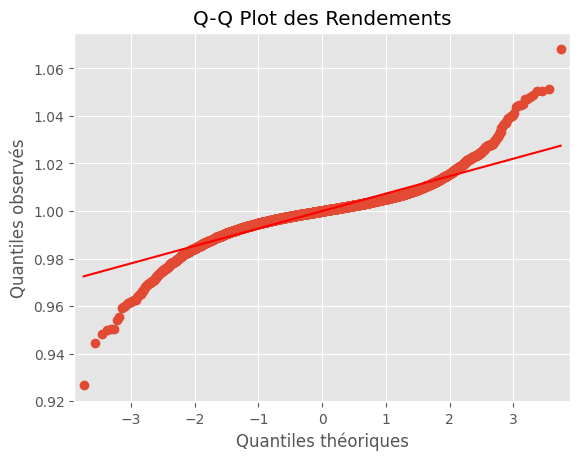

In [ ]:
# Q-Q plot des rendements

plt.figure(figsize=(8, 6))
sm.qqplot(BTCUSDT['rendement'], line='s', color=(0.0, 0.0, 1.0, 1))
plt.title('Q-Q Plot des Rendements')
plt.xlabel('Quantiles théoriques')
plt.ylabel('Quantiles observés')
plt.grid(True)
plt.show()

In [ ]:
# Calculate the kurtosis and skewness of 'rendement'

kurtosis_value = BTCUSDT['rendement'].kurtosis()
skewness_value = BTCUSDT['rendement'].skew()
print("Kurtosis:", kurtosis_value)
print("Skewness:", skewness_value)

Kurtosis: 8.260114887883962
Skewness: 0.019831155449175873


La kurtosis indique que la distribution a une concentration de valeurs plus importante autour de la moyenne par rapport à la distribution normale. La skewness est proche de 0 indiquant une légère asymétrie vers la droite de la distribution, mais la distribution est principalement symétrique.

In [ ]:
# Shapiro-Wilk test for normality

statistic, p_value = shapiro(BTCUSDT['rendement'])
print("Test Statistic:", statistic)
print("P-value:", p_value)

# Check if the null hypothesis of normality is rejected or not

if p_value > 0.05:
    print("The null hypothesis of normality is not rejected (fail to reject H0)")
else:
    print("The null hypothesis of normality is rejected (reject H0)")

Test Statistic: 0.9051348578988743
P-value: 3.101915529938696e-63
The null hypothesis of normality is rejected (reject H0)


In [ ]:
# Kolmogorov-Smirnov test for normality

statistic, p_value = kstest(BTCUSDT['rendement'], 'norm')
print("Test Statistic:", statistic)
print("P-value:", p_value)

# Check if the null hypothesis is rejected

if p_value > 0.05:
    print("The null hypothesis of normality is not rejected (fail to reject H0)")
else:
    print("The null hypothesis of normality is rejected (reject H0)")

Test Statistic: 0.8308458172998147
P-value: 0.0
The null hypothesis of normality is rejected (reject H0)


Normalization of the 'rendement' column

In [ ]:
from sklearn.preprocessing import QuantileTransformer
# Créez une instance de QuantileTransformer
quantile_transformer = QuantileTransformer( n_quantiles=4000, output_distribution='normal', ignore_implicit_zeros=False, subsample=10000, random_state=None, copy=False)
returns_2d = BTCUSDT['rendement'].values.reshape(-1, 1)
# Ajustez et transformez les rendements
transformed_returns = quantile_transformer.fit_transform(returns_2d)
print(BTCUSDT)

                      date      open     close      high       low  rendement
0      2021-06-01 00:00:00  36881.53  37287.29  37500.00  36794.25   1.682470
1      2021-06-01 01:00:00  37287.30  37780.96  37893.76  37100.00   1.857432
2      2021-06-01 02:00:00  37780.96  37237.17  37787.94  37233.00  -1.899420
3      2021-06-01 03:00:00  37237.17  36831.99  37296.83  36600.00  -1.633805
4      2021-06-01 04:00:00  36832.00  36713.97  37118.71  36458.48  -0.670346
...                    ...       ...       ...       ...       ...        ...
10987  2022-09-01 19:00:00  19728.50  19804.30  19930.00  19695.80   0.783024
10988  2022-09-01 20:00:00  19804.20  19855.70  19892.60  19770.10   0.555265
10989  2022-09-01 21:00:00  19855.60  20066.40  20093.30  19830.40   1.654000
10990  2022-09-01 22:00:00  20066.40  20086.10  20153.60  20029.20   0.216126
10991  2022-09-01 23:00:00  20086.10  20062.60  20171.00  20057.70  -0.253333

[10992 rows x 6 columns]


In [ ]:
BTCUSDT['date'] = pd.to_datetime(BTCUSDT['date'])

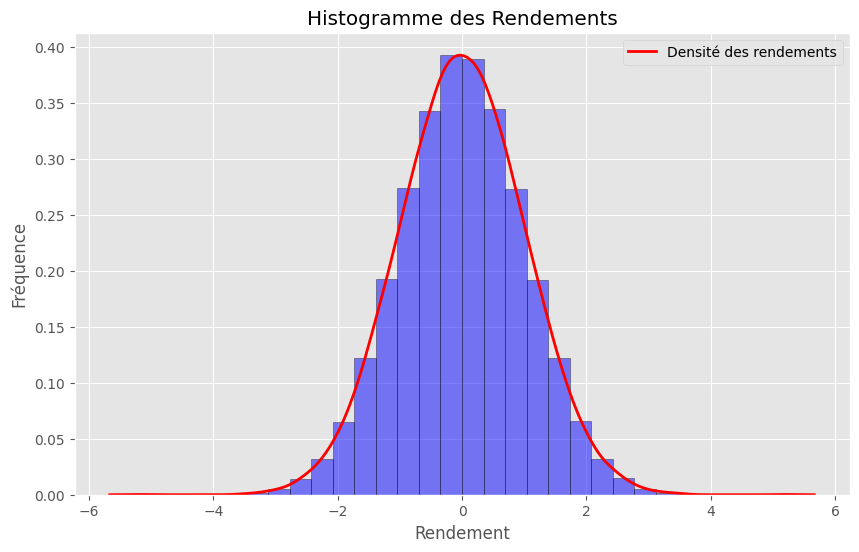

In [ ]:
# L'histogramme et la densité des rendements de 'ETHUSDT'

plt.figure(figsize=(10, 6))
plt.hist(BTCUSDT['rendement'], bins=30, alpha=0.5, color='blue', edgecolor='black', density=True)
plt.title('Histogramme des Rendements')
plt.xlabel('Rendement')
plt.ylabel('Fréquence')
sns.kdeplot(BTCUSDT['rendement'], color='red', linestyle='-', linewidth=2)
plt.legend(['Densité des rendements'])
plt.show()

<Figure size 800x600 with 0 Axes>

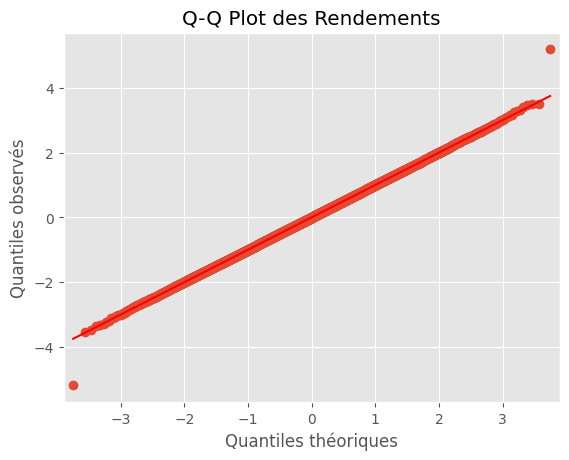

In [ ]:
# Q-Q plot des rendements

plt.figure(figsize=(8, 6))
sm.qqplot(BTCUSDT['rendement'], line='s', color=(0.0, 0.0, 1.0, 1))
plt.title('Q-Q Plot des Rendements')
plt.xlabel('Quantiles théoriques')
plt.ylabel('Quantiles observés')
plt.grid(True)
plt.show()

In [ ]:
# Kolmogorov-Smirnov test for normality

statistic, p_value = kstest(BTCUSDT['rendement'], 'norm')
print("Test Statistic:", statistic)
print("P-value:", p_value)

# Check if the null hypothesis is rejected

if p_value > 0.05:
    print("The null hypothesis of normality is not rejected (fail to reject H0)")
else:
    print("The null hypothesis of normality is rejected (reject H0)")

Test Statistic: 0.0019970813360937756
P-value: 0.9999999999891972
The null hypothesis of normality is not rejected (fail to reject H0)


In [ ]:
BTCUSDT['date'] = pd.to_datetime(BTCUSDT['date'])
BTCUSDT.set_index('date',inplace=True)
BTCUSDT = BTCUSDT[BTCUSDT.index >'2017']
BTCUSDT.head()

,open,close,high,low,rendement
date,,,,,
2021-06-01 00:00:00,36881.53,37287.29,37500.00,36794.25,1.682470
2021-06-01 01:00:00,37287.30,37780.96,37893.76,37100.00,1.857432
2021-06-01 02:00:00,37780.96,37237.17,37787.94,37233.00,-1.899420
2021-06-01 03:00:00,37237.17,36831.99,37296.83,36600.00,-1.633805
2021-06-01 04:00:00,36832.00,36713.97,37118.71,36458.48,-0.670346


In [ ]:
num_days_pred = 365

In [ ]:
def mean_absolute_percentage_error(y_true, y_pred):
    """Calculates MAPE given y_true and y_pred"""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def add_lags(BTCUSDT,num_days_pred=num_days_pred):
    target = 'close'
    BTCUSDT['lag1'] = BTCUSDT[target].shift(num_days_pred)
    BTCUSDT['lag2'] = BTCUSDT[target].shift(num_days_pred*2)
    BTCUSDT['lag3'] = BTCUSDT[target].shift(num_days_pred*3)
    BTCUSDT['lag4'] = BTCUSDT[target].shift(num_days_pred*4)

    return  BTCUSDT

def create_features( BTCUSDT):
    """
    Create time series features based on time series index.
    """
    BTCUSDT = BTCUSDT.copy()
    BTCUSDT['hour'] = BTCUSDT.index.hour
    BTCUSDT['dayofweek'] = BTCUSDT.index.dayofweek
    BTCUSDT['quarter'] = BTCUSDT.index.quarter
    BTCUSDT['month'] = BTCUSDT.index.month
    BTCUSDT['year'] = BTCUSDT.index.year
    BTCUSDT['dayofyear'] = BTCUSDT.index.dayofyear
    BTCUSDT['dayofmonth'] = BTCUSDT.index.day
    BTCUSDT['weekofyear'] = BTCUSDT.index.isocalendar().week
    return BTCUSDT

In [ ]:
if 'Close' in BTCUSDT.columns:
    BTCUSDT['lag1'] = BTCUSDT['Close'].shift(num_days_pred)
else:
    print("La colonne 'Close' est absente du DataFrame.")


La colonne 'Close' est absente du DataFrame.


In [ ]:
print(BTCUSDT.columns)


Index(['open', 'close', 'high', 'low', 'rendement'], dtype='object')


In [ ]:
# Génération des variables explicatives (features)
BTCUSDT = create_features(BTCUSDT)
BTCUSDT = add_lags(BTCUSDT)

# Suppression des lignes contenant des NaN introduits par les lags de 365 jours
BTCUSDT_clean = BTCUSDT.dropna()

# Éviter le data leakage : On retire absolument 'open', 'high', 'low', 'rendement' de X
X = BTCUSDT_clean.drop(columns=['close', 'open', 'high', 'low', 'rendement'])
y = BTCUSDT_clean['close']

In [ ]:
# Séparation chronologique (Time Series Split) au lieu de train_test_split aléatoire
split_idx = int(len(X) * 0.7)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Définition de l'objectif d'optimisation pour Optuna
def objective(trial):
    param = {
        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 10),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 10),
        'verbosity': 0
    }

    xgb = XGBRegressor(**param)
    xgb.fit(X_train, y_train)
    y_pred = xgb.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    return rmse

# Optimisation avec Optuna
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=10)

# Extraction des meilleurs hyperparamètres
best_params = study.best_trial.params
print("Best params:", best_params)

# Entraînement du modèle final xgb_best avec les meilleurs paramètres
xgb_best = XGBRegressor(**best_params)
xgb_best.fit(X_train, y_train)

# Prédictions sur l'ensemble de test
y_pred_test = xgb_best.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
print("Test RMSE:", rmse_test)

[I 2026-11-14 06:53:20,530] A new study created in memory with name: no-name-99977db4-8039-4c01-8ca8-ce7704675905
[I 2026-11-14 06:53:20,999] Trial 0 finished with value: 18115.60122947145 and parameters: {'n_estimators': 406, 'max_depth': 5, 'learning_rate': 0.09813515841136196, 'subsample': 0.6959123979708579, 'colsample_bytree': 0.6110811455800352, 'reg_alpha': 7.630086016669385, 'reg_lambda': 4.29901461653953}. Best is trial 0 with value: 18115.60122947145.
[I 2026-11-14 06:53:22,021] Trial 1 finished with value: 18035.004295474653 and parameters: {'n_estimators': 813, 'max_depth': 3, 'learning_rate': 0.039488714903117075, 'subsample': 0.9607498383792918, 'colsample_bytree': 0.7298784903163533, 'reg_alpha': 9.48042150875334, 'reg_lambda': 6.190031488348449}. Best is trial 1 with value: 18035.004295474653.
[I 2026-11-14 06:53:22,756] Trial 2 finished with value: 18078.109845696905 and parameters: {'n_estimators': 915, 'max_depth': 4, 'learning_rate': 0.06326529334116703, 'subsample'

Best params: {'n_estimators': 613, 'max_depth': 3, 'learning_rate': 0.05172406026274243, 'subsample': 0.8592929279429579, 'colsample_bytree': 0.757504987851828, 'reg_alpha': 3.9785007838700146, 'reg_lambda': 8.692409580234964}
Test RMSE: 17873.057413837654


In [ ]:
y_pred = xgb_best.predict(X_test)
xgb_loss = mean_absolute_percentage_error(y_test, y_pred)
print(f"ERROR PERCENT = { mean_absolute_percentage_error(y_test, y_pred) }% ")

ERROR PERCENT = 74.56988581418507% 


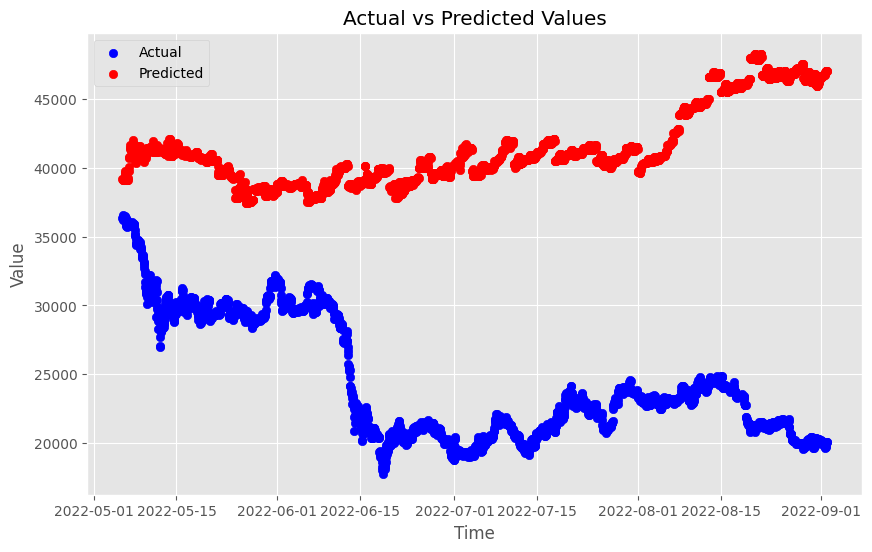

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test.index, y_test, color='blue', label='Actual')
plt.scatter(X_test.index, y_pred , color='red', label='Predicted')
plt.title('Actual vs Predicted Values')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

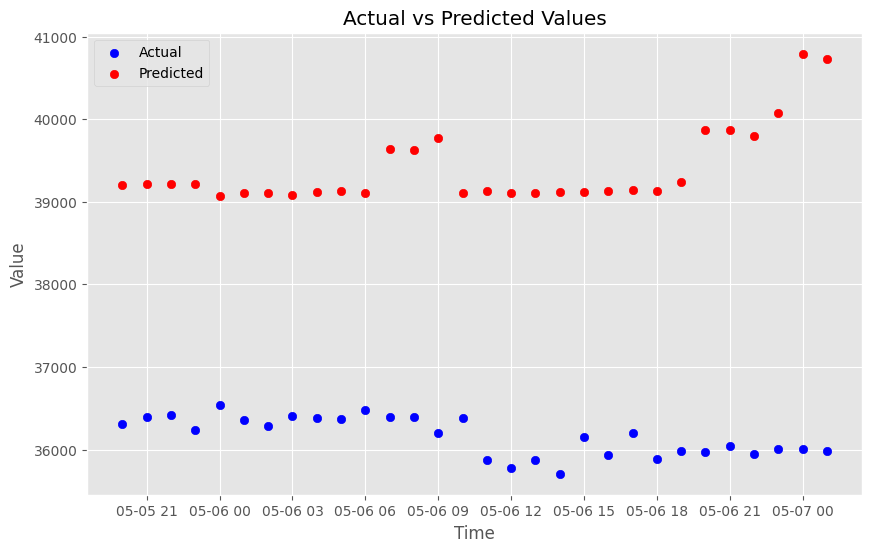

In [ ]:
# Let's ZoomIn
plt.figure(figsize=(10, 6))
plt.scatter(X_test.index[:30], y_test[:30], color='blue', label='Actual')
plt.scatter(X_test.index[:30], y_pred[:30] , color='red', label='Predicted')
plt.title('Actual vs Predicted Values')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

<Figure size 1000x600 with 0 Axes>

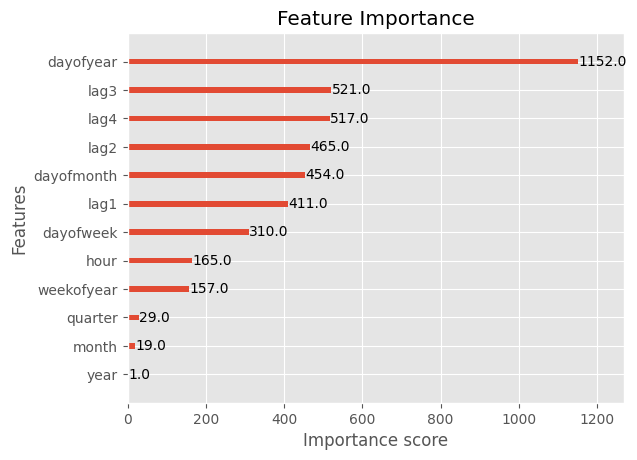

In [ ]:
from xgboost import plot_importance

# Plot feature importance
plt.figure(figsize=(10, 6))
plot_importance(xgb_best, max_num_features=20)  # Adjust max_num_features as needed
plt.title("Feature Importance")
plt.show()

In [ ]:
start = BTCUSDT.index.max()
end = start + pd.Timedelta(days=num_days_pred)

In [ ]:
future = pd.date_range(start=start,end=end,freq='1d')
future_BTCUSDT = pd.DataFrame(index=future)
future_BTCUSDT['isFuture']= True
BTCUSDT['isFuture']= False
BTCUSDT_and_future = pd.concat([BTCUSDT,future_BTCUSDT])
BTCUSDT_and_future = create_features(BTCUSDT_and_future)
BTCUSDT_and_future = add_lags(BTCUSDT_and_future)
future_w_features = BTCUSDT_and_future.query('isFuture').copy()

In [ ]:
# Prédiction pour le futur en supprimant les colonnes non nécessaires pour éviter les erreurs d'alignement de features
features_cols = X.columns.tolist()
future_w_features['pred'] = xgb_best.predict(future_w_features[features_cols])

In [ ]:
prediction_xgb = pd.DataFrame(future_w_features['pred'])
prediction_xgb

In [ ]:
BTCUSDT.close.max()

68688.01

Text(0.5, 1.0, 'Prediction Of Bitcoin Price For The Next 365 Days')

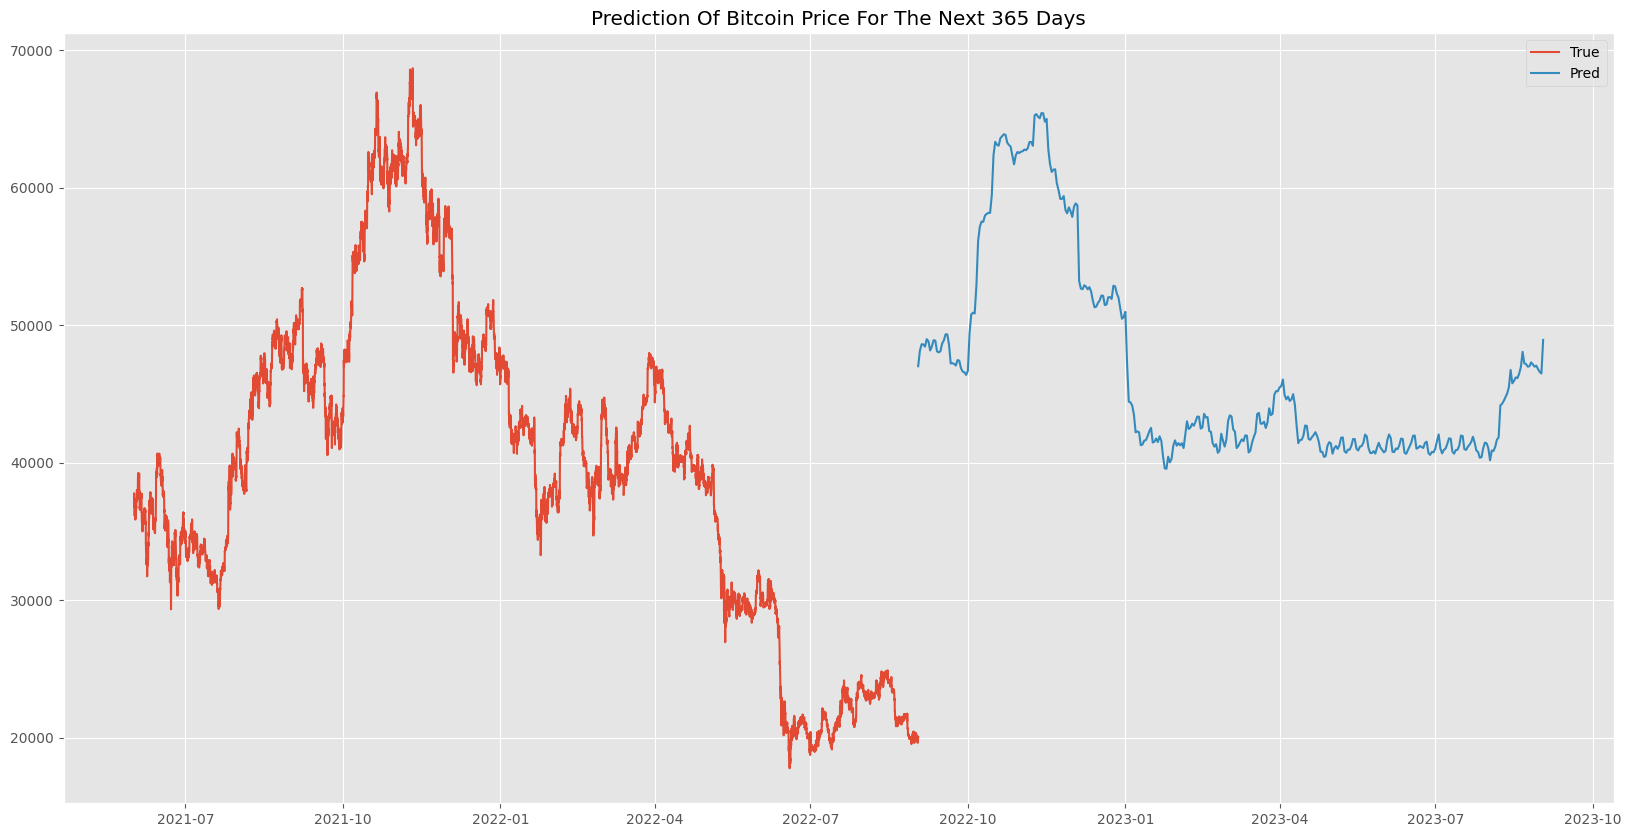

In [ ]:
# Définition de la variable manquante pour éviter l'erreur
prediction_xgb = future_w_features['pred']

plt.subplots(figsize=(20,10))
plt.plot(BTCUSDT['close'])
plt.plot(prediction_xgb)
plt.legend(['True','Pred'])
plt.title(f'Prediction Of Bitcoin Price For The Next {num_days_pred} Days')